# Monitor de límites de apetito: del semáforo estático a una alerta que no cansa

**Perfil:** Riesgo de crédito (estrategia y portafolio)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un semáforo con umbral fijo sobre una utilización ruidosa produce alarmas que parpadean y falsas alarmas. ¿Qué reglas (persistencia, histéresis, suavizado, proyección de tendencia) reducen el ruido **sin perder las violaciones reales**, y cuánto se paga en demora de detección?

## Recorrido

1. Series simuladas de utilización de 20 límites con una **violación real latente** (episodios con rampa) y ruido de medición autocorrelacionado.
2. **Versión 1:** semáforo estático.
3. **Diagnóstico:** falsas alarmas, parpadeo y demora, contra la verdad conocida.
4. **Versiones 2 y 3:** persistencia + histéresis; luego suavizado exponencial y proyección de tendencia (pre-alerta).
5. **Curva de operación:** compromiso entre detección y falsas alarmas para cada regla, con incertidumbre.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 2. Datos con verdad conocida

Cada límite tiene un **nivel latente** de utilización $L_t$ (la verdad) y una medición ruidosa $u_t=L_t+\eta_t$ con $\eta_t$ autorregresivo ($\phi=0{,}6$, $\sigma=0{,}045$). Los niveles base están entre 0,78 y 0,97: los límites **operan cerca de su tope**, que es donde el ruido importa.

> *Nota de diseño:* una primera versión de esta simulación usaba niveles base entre 0,45 y 0,80 y un ruido de 0,035. Con esos valores el semáforo estático salía perfecto (recall 100 %, cero falsas alarmas) porque el ruido nunca alcanzaba el límite: no había compromiso que estudiar. El diseño actual pone los límites donde el problema existe. El nivel latente es un nivel base más **episodios** trapezoidales: sube con una rampa, se mantiene sobre 1,0 unos días y vuelve a bajar. Una **violación real** es un tramo continuo de al menos 3 días con $L_t>1$.

(250, 20) | dias con violacion real (L>1): 10.8% | desvio del ruido de medicion: 0.044


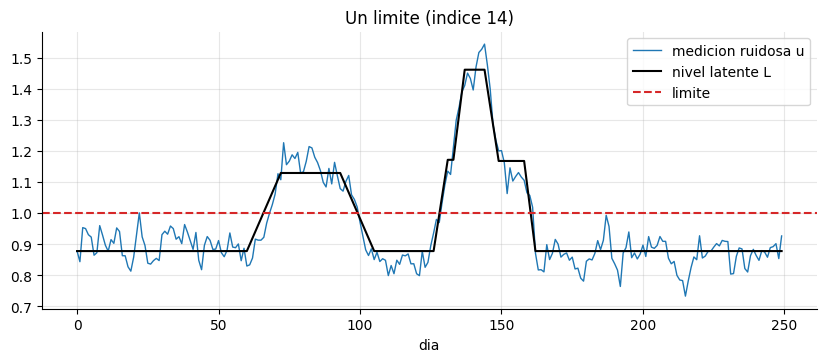

In [2]:
T_DIAS, N_LIMITES = 250, 20
PHI, SIGMA = 0.6, 0.045

def simular(seed, n_lim=N_LIMITES, T=T_DIAS):
    rg = np.random.default_rng(seed)
    base = rg.uniform(0.78, 0.97, n_lim)            # limites que operan CERCA de su tope: ahi el ruido importa
    lat = np.tile(base, (T, 1))
    for j in range(n_lim):
        for _ in range(rg.poisson(1.2)):
            ini = rg.integers(15, T - 50); rampa = rg.integers(5, 16); mant = rg.integers(8, 30)
            pico = rg.uniform(1.03, 1.18) - base[j]
            forma = np.concatenate([np.linspace(0, 1, rampa), np.ones(mant), np.linspace(1, 0, rampa)])
            fin = min(T, ini + len(forma)); lat[ini:fin, j] += pico * forma[:fin - ini]
    eta = np.zeros((T, n_lim)); e = rg.normal(0, SIGMA, (T, n_lim))
    for t in range(1, T):
        eta[t] = PHI * eta[t - 1] + np.sqrt(1 - PHI ** 2) * e[t]
    return lat + eta, lat

U, LAT = simular(2026)
print(U.shape, "| dias con violacion real (L>1):", f"{(LAT > 1).mean():.1%}", "| desvio del ruido de medicion:", f"{(U - LAT).std():.3f}")
fig, ax = plt.subplots(figsize=(10, 3.6))
j = int(np.argmax((LAT > 1).sum(axis=0)))
ax.plot(U[:, j], lw=1, label="medicion ruidosa u"); ax.plot(LAT[:, j], "k", lw=1.5, label="nivel latente L"); ax.axhline(1.0, color="C3", ls="--", label="limite")
ax.set_xlabel("dia"); ax.set_title(f"Un limite (indice {j})"); ax.legend(); plt.show()

### Cómo se evalúa una regla

Una regla convierte la serie $u_t$ en una alarma booleana. Contra la verdad:

- **Recall por episodio:** fracción de violaciones reales con alguna alarma entre $H_{\text{antes}}=10$ días antes del inicio y el final del episodio.
- **Demora:** primer día de alarma menos día de inicio (negativo = **aviso anticipado**).
- **Falsas alarmas:** días con alarma lejos de cualquier violación (fuera de $[\text{inicio}-10,\ \text{fin}+3]$), por cada 100 días-límite.
- **Parpadeo:** transiciones apagado→encendido de la alarma por límite-año fuera de episodios.

In [3]:
H_ANTES, H_DESPUES, MIN_DIAS = 10, 3, 3

def episodios(lat_col):
    viol = lat_col > 1.0
    eps, t = [], 0
    while t < len(viol):
        if viol[t]:
            s = t
            while t < len(viol) and viol[t]: t += 1
            if t - s >= MIN_DIAS: eps.append((s, t - 1))
        else: t += 1
    return eps

def evaluar(regla, U, LAT, **kw):
    det, demoras, n_ep = 0, [], 0
    dias_falsa, dias_total, parpadeos, reaperturas = 0, 0, 0, 0
    for j in range(U.shape[1]):
        alarma = regla(U[:, j], **kw)
        eps = episodios(LAT[:, j]); n_ep += len(eps)
        cerca = np.zeros(len(alarma), bool)
        for s, f in eps:
            lo, hi = max(0, s - H_ANTES), min(len(alarma) - 1, f + H_DESPUES)
            cerca[lo:hi + 1] = True
            ventana = np.where(alarma[lo:f + 1])[0]
            if len(ventana): det += 1; demoras.append(lo + ventana[0] - s)
            seg = alarma[lo:f + 1]
            reaperturas += max(int((seg & ~np.r_[False, seg[:-1]]).sum()) - 1, 0)       # reencendidos dentro de una misma violacion
        falsa = alarma & ~cerca
        dias_falsa += falsa.sum(); dias_total += (~cerca).sum()
        on = alarma & ~np.r_[False, alarma[:-1]]
        parpadeos += (on & ~cerca).sum()
    return {"recall_episodios": det / max(n_ep, 1), "demora_mediana": float(np.median(demoras)) if demoras else np.nan,
            "falsas_alarmas_x100d": dias_falsa / max(dias_total, 1) * 100, "alarmas_falsas_por_limite_anio": parpadeos / U.shape[1] / (U.shape[0] / 365),
            "reaperturas_x_episodio": reaperturas / max(n_ep, 1), "episodios": n_ep}

# prueba de la evaluacion con un caso de juguete antes de usarla
toy_lat = np.zeros((40, 1)); toy_lat[15:25, 0] = 1.1
toy_u = toy_lat.copy()
r_toy = evaluar(lambda u, thr: u >= thr, toy_u, toy_lat, thr=1.0)
assert r_toy["recall_episodios"] == 1.0 and r_toy["demora_mediana"] == 0 and r_toy["falsas_alarmas_x100d"] == 0
toy_u2 = toy_lat.copy(); toy_u2[2:4, 0] = 1.2                       # una falsa alarma lejos del episodio
r_toy2 = evaluar(lambda u, thr: u >= thr, toy_u2, toy_lat, thr=1.0)
assert r_toy2["falsas_alarmas_x100d"] > 0 and r_toy2["alarmas_falsas_por_limite_anio"] > 0
print("la funcion de evaluacion se verifico con casos de juguete")

la funcion de evaluacion se verifico con casos de juguete


## 3. Versión 1: semáforo estático

Rojo si $u_t\ge 1{,}0$ (la regla más simple). Se evalúa sobre 40 réplicas de 20 límites × 250 días para tener una estimación estable.

In [4]:
def regla_estatica(u, thr=1.0):
    return u >= thr

def promedio_reps(regla, reps, **kw):
    filas = [evaluar(regla, *sim, **kw) for sim in reps]
    return pd.DataFrame(filas)

REPS = [simular(1000 + i) for i in range(40)]
r1 = promedio_reps(regla_estatica, REPS, thr=1.0)
r1.describe().loc[["mean", "std"]].round(3)

,recall_episodios,demora_mediana,falsas_alarmas_x100d,alarmas_falsas_por_limite_anio,reaperturas_x_episodio,episodios
mean,1.0000,-0.8000,3.6140,6.3220,1.0160,19.8500
std,0.0000,0.7230,1.1080,1.7880,0.2790,4.1420


In [5]:
m1 = r1.mean()
print("Lectura (semaforo estatico, umbral 1.0):")
print(f"  Detecta el {m1['recall_episodios']:.0%} de las violaciones reales, con una demora mediana de {m1['demora_mediana']:.1f} dias.")
print(f"  Pero produce {m1['falsas_alarmas_x100d']:.2f} dias de falsa alarma por cada 100 dias-limite y {m1['alarmas_falsas_por_limite_anio']:.2f} alarmas falsas por limite al anio.")

Lectura (semaforo estatico, umbral 1.0):
  Detecta el 100% de las violaciones reales, con una demora mediana de -0.8 dias.
  Pero produce 3.61 dias de falsa alarma por cada 100 dias-limite y 6.32 alarmas falsas por limite al anio.


### 3.1 Diagnóstico: parpadeo alrededor del umbral

En el limite 14: 6 cambios de estado (verde<->rojo) en 250 dias, con 2 violaciones reales.
Durante la primera violacion (66-99), la alarma estatica cambia de estado 2 veces.


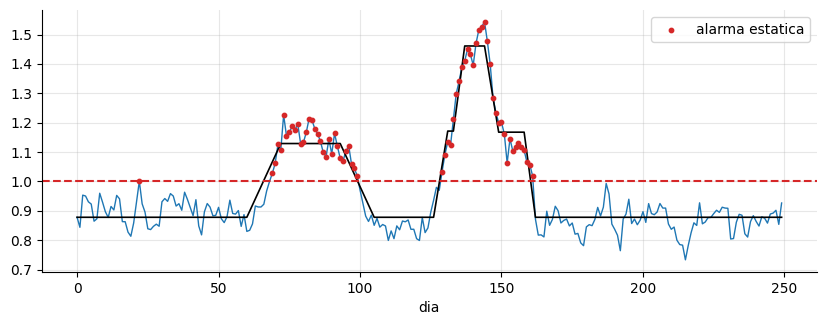

In [6]:
a = regla_estatica(U[:, j])
cambios = np.flatnonzero(np.diff(a.astype(int)) != 0)
ep = episodios(LAT[:, j])
print(f"En el limite {j}: {len(cambios)} cambios de estado (verde<->rojo) en {T_DIAS} dias, con {len(ep)} violaciones reales.")
if ep:
    s, f = ep[0]
    seg = a[s - 5:f + 6]
    print(f"Durante la primera violacion ({s}-{f}), la alarma estatica cambia de estado {int((np.diff(seg.astype(int)) != 0).sum())} veces.")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(U[:, j], lw=1, color="C0"); ax.plot(LAT[:, j], "k", lw=1.2); ax.axhline(1, color="C3", ls="--")
ax.scatter(np.flatnonzero(a), U[a, j], s=10, color="C3", zorder=3, label="alarma estatica"); ax.legend(); ax.set_xlabel("dia"); plt.show()

**Qué muestra.** Cuando el nivel real cruza el umbral, el ruido lo hace oscilar a ambos lados: la alarma **parpadea**. Y cuando el nivel latente está cerca de 1 pero sin pasarlo, el ruido produce falsas alarmas aisladas. Un umbral duro sobre una medición ruidosa confunde los dos problemas.

## 4. Versión 2: persistencia e histéresis

- **Persistencia:** alarma solo si al menos $k$ de los últimos $m$ días están sobre el umbral (por defecto 3 de 5).
- **Histéresis:** una vez encendida, la alarma se apaga solo cuando $u_t$ cae por debajo de un umbral de salida más bajo (0,95), de modo que el ruido cerca de 1,0 no la apague y encienda.

In [7]:
def regla_persistencia(u, thr=1.0, k=3, m=5):
    sobre = (u >= thr).astype(int)
    return np.convolve(sobre, np.ones(m), mode="full")[:len(u)] >= k

def regla_histeresis(u, entrar=1.0, salir=0.95, k=3, m=5):
    sobre = (u >= entrar).astype(int)
    entra = np.convolve(sobre, np.ones(m), mode="full")[:len(u)] >= k
    estado, out = False, np.zeros(len(u), bool)
    for t in range(len(u)):
        if not estado and entra[t]: estado = True
        elif estado and u[t] < salir: estado = False
        out[t] = estado
    return out

r2 = promedio_reps(regla_persistencia, REPS)
r2h = promedio_reps(regla_histeresis, REPS)
comp = pd.DataFrame({"v1 estatica": r1.mean(), "v2a persistencia 3/5": r2.mean(), "v2b persistencia + histeresis": r2h.mean()}).T
comp.round(3)

,recall_episodios,demora_mediana,falsas_alarmas_x100d,alarmas_falsas_por_limite_anio,reaperturas_x_episodio,episodios
v1 estatica,1.0000,-0.8000,3.6140,6.3220,1.0160,19.8500
v2a persistencia 3/5,1.0000,1.9380,1.9880,1.3980,0.1630,19.8500
v2b persistencia + histeresis,1.0000,1.9120,2.3990,1.5840,0.1560,19.8500


In [8]:
print("Lectura:")
for nombre in comp.index[1:]:
    print(f"  {nombre:32s}: falsas alarmas {comp.loc[nombre, 'falsas_alarmas_x100d'] / comp.loc['v1 estatica', 'falsas_alarmas_x100d'] - 1:+.0%} | recall {comp.loc[nombre, 'recall_episodios'] - comp.loc['v1 estatica', 'recall_episodios']:+.1%} pts | demora {comp.loc[nombre, 'demora_mediana'] - comp.loc['v1 estatica', 'demora_mediana']:+.1f} dias")

Lectura:
  v2a persistencia 3/5            : falsas alarmas -45% | recall +0.0% pts | demora +2.7 dias
  v2b persistencia + histeresis   : falsas alarmas -34% | recall +0.0% pts | demora +2.7 dias


## 5. Versión 3: suavizado y proyección de tendencia (pre-alerta)

Las violaciones reales **se acercan con una rampa**: el nivel sube durante varios días antes de cruzar. Una regla que estima la **pendiente** puede avisar antes de cruzar:

1. **EWMA:** $s_t=\lambda u_t+(1-\lambda)s_{t-1}$ (con $\lambda=0{,}3$); alarma si $s_t\ge \text{thr}$.
2. **Proyección:** se ajusta una recta a los últimos $w=7$ días del EWMA y se proyecta $h=5$ días adelante; alarma si la proyección supera el umbral y el nivel actual ya supera un piso (0,85) para evitar avisar por ruido en niveles bajos.

In [9]:
def ewma(u, lam=0.3):
    s = np.empty(len(u)); s[0] = u[0]
    for t in range(1, len(u)): s[t] = lam * u[t] + (1 - lam) * s[t - 1]
    return s

def regla_ewma(u, thr=1.0, lam=0.3):
    return ewma(u, lam) >= thr

def regla_tendencia(u, thr=1.0, lam=0.3, w=7, h=5, piso=0.85):
    s = ewma(u, lam); out = np.zeros(len(u), bool)
    x = np.arange(w)
    for t in range(w - 1, len(u)):
        y = s[t - w + 1:t + 1]
        pend = np.polyfit(x, y, 1)[0]
        out[t] = (s[t] >= thr) or (s[t] >= piso and s[t] + pend * h >= thr)
    return out

r3a = promedio_reps(regla_ewma, REPS)
r3b = promedio_reps(regla_tendencia, REPS)
comp = pd.DataFrame({"v1 estatica": r1.mean(), "v2b persistencia + histeresis": r2h.mean(), "v3a EWMA": r3a.mean(), "v3b EWMA + tendencia": r3b.mean()}).T
comp.round(3)

,recall_episodios,demora_mediana,falsas_alarmas_x100d,alarmas_falsas_por_limite_anio,reaperturas_x_episodio,episodios
v1 estatica,1.0000,-0.8000,3.6140,6.3220,1.0160,19.8500
v2b persistencia + histeresis,1.0000,1.9120,2.3990,1.5840,0.1560,19.8500
v3a EWMA,1.0000,1.8750,1.3390,1.1860,0.1680,19.8500
v3b EWMA + tendencia,1.0000,-0.6880,5.2210,4.4580,0.2670,19.8500


In [10]:
print("Lectura (parametros por defecto de cada regla):")
for nombre in comp.index:
    c = comp.loc[nombre]
    print(f"  {nombre:32s}: dias de falsa alarma x100 = {c['falsas_alarmas_x100d']:.2f} | alarmas falsas/limite-anio = {c['alarmas_falsas_por_limite_anio']:.2f} | reaperturas por violacion = {c['reaperturas_x_episodio']:.2f} | demora mediana = {c['demora_mediana']:+.1f} d")
v3b, v1_ = comp.loc["v3b EWMA + tendencia"], comp.loc["v1 estatica"]
print(f"  La regla de tendencia tiene {v3b['falsas_alarmas_x100d'] / v1_['falsas_alarmas_x100d'] - 1:+.0%} dias de falsa alarma que la estatica y una demora de {v3b['demora_mediana']:+.1f} d (estatica {v1_['demora_mediana']:+.1f} d): {'NO avisa antes' if v3b['demora_mediana'] > v1_['demora_mediana'] - 0.5 else 'avisa antes'}.")

Lectura (parametros por defecto de cada regla):
  v1 estatica                     : dias de falsa alarma x100 = 3.61 | alarmas falsas/limite-anio = 6.32 | reaperturas por violacion = 1.02 | demora mediana = -0.8 d
  v2b persistencia + histeresis   : dias de falsa alarma x100 = 2.40 | alarmas falsas/limite-anio = 1.58 | reaperturas por violacion = 0.16 | demora mediana = +1.9 d
  v3a EWMA                        : dias de falsa alarma x100 = 1.34 | alarmas falsas/limite-anio = 1.19 | reaperturas por violacion = 0.17 | demora mediana = +1.9 d
  v3b EWMA + tendencia            : dias de falsa alarma x100 = 5.22 | alarmas falsas/limite-anio = 4.46 | reaperturas por violacion = 0.27 | demora mediana = -0.7 d
  La regla de tendencia tiene +44% dias de falsa alarma que la estatica y una demora de -0.7 d (estatica -0.8 d): NO avisa antes.


Una cautela de interpretación: comparar reglas **con umbrales distintos** no es justo, porque cada una tiene un compromiso propio entre detección y falsas alarmas. La comparación honesta es a **igual tasa de falsas alarmas**, y eso se hace en la sección siguiente.

### 5.1 ¿Se puede salvar la regla de tendencia? Sensibilidad de sus dos parámetros

La hipótesis de la pre-alerta era que la pendiente adelanta el cruce. Se prueba si **algún** par (piso, horizonte) logra **a la vez** avisar antes y no tener más falsas alarmas que la estática.

In [11]:
filas = []
for piso in (0.85, 0.90, 0.95):
    for h in (3, 5, 8):
        d = promedio_reps(regla_tendencia, REPS[:10], piso=piso, h=h).mean()
        filas.append({"piso": piso, "horizonte": h, "falsas_x100d": d["falsas_alarmas_x100d"], "demora": d["demora_mediana"], "reaperturas": d["reaperturas_x_episodio"]})
sens_t = pd.DataFrame(filas)
est = promedio_reps(regla_estatica, REPS[:10]).mean()
sens_t["avisa_antes_y_no_peor"] = (sens_t["demora"] < est["demora_mediana"] - 0.5) & (sens_t["falsas_x100d"] <= est["falsas_alarmas_x100d"])
print(f"Referencia (estatica, mismas 10 replicas): falsas x100d = {est['falsas_alarmas_x100d']:.2f}, demora = {est['demora_mediana']:+.1f} d")
sens_t.round(2)

Referencia (estatica, mismas 10 replicas): falsas x100d = 3.64, demora = -0.8 d


,piso,horizonte,falsas_x100d,demora,reaperturas,avisa_antes_y_no_peor
0,0.8500,3,3.4000,0.4000,0.2300,False
1,0.8500,5,5.2300,-0.7000,0.2800,False
2,0.8500,8,8.2800,-1.5000,0.3000,False
3,0.9000,3,3.4000,0.4000,0.2300,False
4,0.9000,5,5.2300,-0.6500,0.2700,False
5,0.9000,8,8.0000,-1.3000,0.2800,False
6,0.9500,3,3.4000,0.5500,0.2300,False
7,0.9500,5,4.9000,0.3000,0.2400,False
8,0.9500,8,6.3400,0.2000,0.2200,False


In [12]:
n_ok = int(sens_t["avisa_antes_y_no_peor"].sum())
print(f"Lectura: {n_ok} de {len(sens_t)} combinaciones avisan antes (>0.5 d) sin aumentar los dias de falsa alarma respecto de la estatica.")
mejor = sens_t.sort_values("falsas_x100d").iloc[0]
print(f"La combinacion con menos falsas alarmas (piso {mejor['piso']}, horizonte {int(mejor['horizonte'])}) tiene {mejor['falsas_x100d']:.2f} falsas x100d y demora {mejor['demora']:+.1f} d.")

Lectura: 0 de 9 combinaciones avisan antes (>0.5 d) sin aumentar los dias de falsa alarma respecto de la estatica.
La combinacion con menos falsas alarmas (piso 0.95, horizonte 3) tiene 3.40 falsas x100d y demora +0.6 d.


## 6. Curva de operación: comparar a igual presupuesto de falsas alarmas

Para cada regla se barre su umbral y se mide **detección** (recall de episodios) contra **dos** costos distintos de las falsas alarmas:

- **Días** de falsa alarma por 100 días-límite (cuánto tiempo la alarma está encendida sin motivo).
- **Alarmas falsas distintas por límite-año** (cuántas veces suena sin motivo): es lo que produce **fatiga** en quien las atiende.

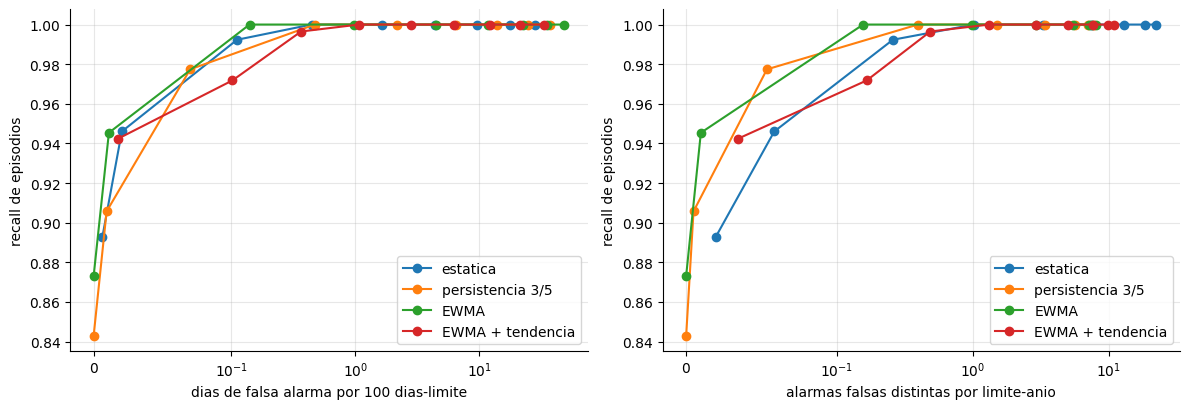

In [13]:
def barrido(regla, umbrales, reps=REPS[:15], **kw):
    filas = []
    for thr in umbrales:
        d = promedio_reps(regla, reps, thr=thr, **kw).mean()
        filas.append({"thr": thr, "recall": d["recall_episodios"], "falsas_x100d": d["falsas_alarmas_x100d"],
                      "falsas_por_anio": d["alarmas_falsas_por_limite_anio"], "demora": d["demora_mediana"], "reaperturas": d["reaperturas_x_episodio"]})
    return pd.DataFrame(filas)

curvas = {
    "estatica": barrido(regla_estatica, np.linspace(0.92, 1.12, 9)),
    "persistencia 3/5": barrido(regla_persistencia, np.linspace(0.90, 1.10, 9)),
    "EWMA": barrido(regla_ewma, np.linspace(0.88, 1.08, 9)),
    "EWMA + tendencia": barrido(regla_tendencia, np.linspace(0.92, 1.12, 9)),
}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for nombre, cv in curvas.items():
    ax[0].plot(cv["falsas_x100d"], cv["recall"], "o-", label=nombre); ax[1].plot(cv["falsas_por_anio"], cv["recall"], "o-", label=nombre)
ax[0].set_xlabel("dias de falsa alarma por 100 dias-limite"); ax[1].set_xlabel("alarmas falsas distintas por limite-anio")
for a_ in ax: a_.set_ylabel("recall de episodios"); a_.set_xscale("symlog", linthresh=0.1); a_.legend()
plt.tight_layout(); plt.show()

In [14]:
def mejor_a_presupuesto(cv, col, presupuesto, recall_min=None):
    ok = cv[cv[col] <= presupuesto]
    return float(ok["recall"].max()) if len(ok) else np.nan

filas = []
for pres in (0.3, 1.0, 3.0):
    filas.append({"presupuesto": f"{pres} dias x100", **{n: mejor_a_presupuesto(cv, "falsas_x100d", pres) for n, cv in curvas.items()}})
for pres in (0.5, 1.0, 2.0):
    filas.append({"presupuesto": f"{pres} alarmas/anio", **{n: mejor_a_presupuesto(cv, "falsas_por_anio", pres) for n, cv in curvas.items()}})
tab_pres = pd.DataFrame(filas).set_index("presupuesto")
print("Mayor recall alcanzable con cada presupuesto de falsas alarmas:")
tab_pres.round(3)

Mayor recall alcanzable con cada presupuesto de falsas alarmas:


,estatica,persistencia 3/5,EWMA,EWMA + tendencia
presupuesto,,,,
0.3 dias x100,0.9920,0.9770,1.0000,0.9720
1.0 dias x100,1.0000,1.0000,1.0000,0.9960
3.0 dias x100,1.0000,1.0000,1.0000,1.0000
0.5 alarmas/anio,0.9920,1.0000,1.0000,0.9960
1.0 alarmas/anio,0.9920,1.0000,1.0000,0.9960
2.0 alarmas/anio,1.0000,1.0000,1.0000,1.0000


In [15]:
# configuracion de cada regla con el MENOR costo de fatiga entre las que logran recall >= 99%
filas = []
for nombre, cv in curvas.items():
    ok = cv[cv["recall"] >= 0.99]
    if len(ok):
        r = ok.sort_values("falsas_por_anio").iloc[0]
        filas.append({"regla": nombre, "umbral": r["thr"], "recall": r["recall"], "falsas_x100d": r["falsas_x100d"], "alarmas_falsas/anio": r["falsas_por_anio"], "reaperturas": r["reaperturas"], "demora_d": r["demora"]})
op99 = pd.DataFrame(filas).set_index("regla")
print("Con recall >= 99%, la configuracion que menos alarmas falsas distintas produce:")
op99.round(3)

Con recall >= 99%, la configuracion que menos alarmas falsas distintas produce:


,umbral,recall,falsas_x100d,alarmas_falsas/anio,reaperturas,demora_d
regla,,,,,,
estatica,1.0700,0.9920,0.1110,0.2580,1.7090,2.2330
persistencia 3/5,1.0250,1.0000,0.4700,0.3940,0.2260,2.8330
EWMA,1.0300,1.0000,0.1400,0.1560,0.2660,3.4000
EWMA + tendencia,1.0700,0.9960,0.3650,0.4870,0.5530,1.2330


In [16]:
print("Lectura:")
mejor_dias = op99["falsas_x100d"].idxmin(); mejor_fat = op99["alarmas_falsas/anio"].idxmin(); mas_rapida = op99["demora_d"].idxmin()
print(f"  A recall >= 99%, la regla con MENOS dias de falsa alarma es '{mejor_dias}' ({op99.loc[mejor_dias, 'falsas_x100d']:.2f} x100d); la que produce menos alarmas distintas es '{mejor_fat}' ({op99.loc[mejor_fat, 'alarmas_falsas/anio']:.2f}/anio); la mas rapida, '{mas_rapida}' ({op99.loc[mas_rapida, 'demora_d']:+.1f} d).")
e_ = op99.loc["estatica"]
print(f"  La estatica con el umbral ajustado a {e_['umbral']:.3f} logra {e_['falsas_x100d']:.2f} dias x100 y {e_['alarmas_falsas/anio']:.2f} alarmas falsas/anio. Ojo: un umbral de {e_['umbral']:.2f} sobre un limite de 1.0 equivale a TOLERAR un exceso de {(e_['umbral'] - 1) * 100:.0f}% antes de alarmar: es una decision de politica, no un ajuste tecnico.")
print(f"  En alarmas distintas por anio (a recall >= 99%): " + ", ".join(f"{n} {op99.loc[n, 'alarmas_falsas/anio']:.2f}" for n in op99.index) + ".")
print(f"  En reaperturas durante una violacion real: " + ", ".join(f"{n} {op99.loc[n, 'reaperturas']:.2f}" for n in op99.index) + f". La estatica reabre {op99.loc['estatica', 'reaperturas'] / op99.loc['EWMA', 'reaperturas']:.0f} veces mas que el EWMA.")
print("  Conclusion: tras ajustar umbrales, la ventaja de persistencia y suavizado esta sobre todo en las REAPERTURAS durante una violacion (alarma que parpadea); en alarmas falsas distintas solo el EWMA mejora a la estatica ajustada.")

Lectura:
  A recall >= 99%, la regla con MENOS dias de falsa alarma es 'estatica' (0.11 x100d); la que produce menos alarmas distintas es 'EWMA' (0.16/anio); la mas rapida, 'EWMA + tendencia' (+1.2 d).
  La estatica con el umbral ajustado a 1.070 logra 0.11 dias x100 y 0.26 alarmas falsas/anio. Ojo: un umbral de 1.07 sobre un limite de 1.0 equivale a TOLERAR un exceso de 7% antes de alarmar: es una decision de politica, no un ajuste tecnico.
  En alarmas distintas por anio (a recall >= 99%): estatica 0.26, persistencia 3/5 0.39, EWMA 0.16, EWMA + tendencia 0.49.
  En reaperturas durante una violacion real: estatica 1.71, persistencia 3/5 0.23, EWMA 0.27, EWMA + tendencia 0.55. La estatica reabre 6 veces mas que el EWMA.
  Conclusion: tras ajustar umbrales, la ventaja de persistencia y suavizado esta sobre todo en las REAPERTURAS durante una violacion (alarma que parpadea); en alarmas falsas distintas solo el EWMA mejora a la estatica ajustada.


## 7. Robustez: incertidumbre entre réplicas y sensibilidad al ruido

In [17]:
filas = []
for nombre, regla, kw in (("estatica", regla_estatica, {}), ("persistencia + histeresis", regla_histeresis, {}), ("EWMA + tendencia", regla_tendencia, {})):
    d = promedio_reps(regla, REPS, **kw)
    filas.append({"regla": nombre, "recall_media": d["recall_episodios"].mean(), "recall_sd": d["recall_episodios"].std(), "falsas_media": d["falsas_alarmas_x100d"].mean(), "falsas_sd": d["falsas_alarmas_x100d"].std()})
inc = pd.DataFrame(filas).set_index("regla")
inc["IC95_recall(+-)"] = 1.96 * inc["recall_sd"] / np.sqrt(len(REPS))
inc.round(4)

,recall_media,recall_sd,falsas_media,falsas_sd,IC95_recall(+-)
regla,,,,,
estatica,1.0000,0.0000,3.6139,1.1082,0.0000
persistencia + histeresis,1.0000,0.0000,2.3987,0.9748,0.0000
EWMA + tendencia,1.0000,0.0000,5.2206,1.3930,0.0000


In [18]:
# sensibilidad: mismo diseño con mas ruido de medicion
def simular_ruido(seed, sigma):
    global SIGMA
    previo = SIGMA; SIGMA = sigma
    try: return simular(seed)
    finally: SIGMA = previo

filas = []
for sig in (0.02, 0.035, 0.06, 0.09):
    reps = [simular_ruido(3000 + i, sig) for i in range(12)]
    for nombre, regla in (("estatica", regla_estatica), ("persistencia + histeresis", regla_histeresis), ("EWMA + tendencia", regla_tendencia)):
        d = promedio_reps(regla, reps).mean()
        filas.append({"sigma_ruido": sig, "regla": nombre, "falsas_x100d": d["falsas_alarmas_x100d"], "recall": d["recall_episodios"]})
sens = pd.DataFrame(filas).pivot(index="sigma_ruido", columns="regla", values=["falsas_x100d", "recall"])
sens.round(3)

falsas_x100d                                     \
regla       EWMA + tendencia estatica persistencia + histeresis   
sigma_ruido                                                       
0.0200                0.7810   0.3340                    0.7170   
0.0350                3.6300   2.2860                    1.9420   
0.0600                9.2390   6.7280                    4.8080   
0.0900               15.9250  12.5160                    8.3940   

                      recall                                     
regla       EWMA + tendencia estatica persistencia + histeresis  
sigma_ruido                                                      
0.0200                1.0000   1.0000                    1.0000  
0.0350                1.0000   1.0000                    1.0000  
0.0600                1.0000   1.0000                    1.0000  
0.0900                1.0000   1.0000                    1.0000

In [19]:
# ¿por que la histeresis tiene MAS dias de falsa alarma con ruido bajo? hipotesis: mantiene la alarma durante la bajada posterior a la violacion
def falsas_post_episodio(regla, reps, **kw):
    post = total = 0
    for U_, L_ in reps:
        for k_ in range(U_.shape[1]):
            al = regla(U_[:, k_], **kw); eps = episodios(L_[:, k_])
            cerca = np.zeros(len(al), bool); tras = np.zeros(len(al), bool)
            for s_, f_ in eps:
                cerca[max(0, s_ - H_ANTES):min(len(al) - 1, f_ + H_DESPUES) + 1] = True
                tras[min(len(al) - 1, f_ + H_DESPUES + 1):min(len(al) - 1, f_ + 20) + 1] = True
            falsa = al & ~cerca
            post += (falsa & tras).sum(); total += falsa.sum()
    return post / max(total, 1), total
reps_bajo = [simular_ruido(3000 + i, 0.02) for i in range(12)]
fp_e, n_e = falsas_post_episodio(regla_estatica, reps_bajo)
fp_h, n_h = falsas_post_episodio(regla_histeresis, reps_bajo)
print(f"Con sigma=0.02: dias de falsa alarma estatica = {n_e}, histeresis = {n_h}.")
print(f"Fraccion de esas falsas alarmas que cae en los 20 dias POSTERIORES a una violacion: estatica {fp_e:.0%}, histeresis {fp_h:.0%}.")
print("Lectura: " + ("la histeresis mantiene la alarma durante la bajada posterior a la violacion, y eso se cuenta como falsa alarma (hipotesis confirmada)." if fp_h > 0.5 and fp_h > fp_e + 0.2 else "la hipotesis de la cola posterior NO explica por completo la diferencia."))
print()
print("Lectura: a medida que sube el ruido,")
for nombre in ("estatica", "persistencia + histeresis", "EWMA + tendencia"):
    f = sens[("falsas_x100d", nombre)]
    print(f"  {nombre:28s}: falsas alarmas x100d de {f.iloc[0]:.2f} (sigma={f.index[0]}) a {f.iloc[-1]:.2f} (sigma={f.index[-1]})")

Con sigma=0.02: dias de falsa alarma estatica = 160, histeresis = 345.
Fraccion de esas falsas alarmas que cae en los 20 dias POSTERIORES a una violacion: estatica 14%, histeresis 64%.
Lectura: la histeresis mantiene la alarma durante la bajada posterior a la violacion, y eso se cuenta como falsa alarma (hipotesis confirmada).

Lectura: a medida que sube el ruido,
  estatica                    : falsas alarmas x100d de 0.33 (sigma=0.02) a 12.52 (sigma=0.09)
  persistencia + histeresis   : falsas alarmas x100d de 0.72 (sigma=0.02) a 8.39 (sigma=0.09)
  EWMA + tendencia            : falsas alarmas x100d de 0.78 (sigma=0.02) a 15.93 (sigma=0.09)


## 8. Pruebas automáticas

In [20]:
# 8.1 maquina de estados de la histeresis: dentro de la banda [salir, entrar) el estado no cambia
u_t = np.array([0.5, 1.1, 1.1, 1.1, 1.1, 1.1, 0.98, 0.97, 0.99, 0.96, 0.94, 0.5])
a_h = regla_histeresis(u_t, entrar=1.0, salir=0.95, k=3, m=5)
assert a_h[6:10].all() and not a_h[10], "la alarma debe mantenerse en la banda y apagarse bajo el umbral de salida"
assert not regla_histeresis(np.full(30, 0.97), 1.0, 0.95).any(), "dentro de la banda sin haber entrado no se enciende"
# 8.2 persistencia: una excursion aislada de 1-2 dias no enciende la alarma con 3/5
u_ais = np.full(20, 0.8); u_ais[8:10] = 1.3
assert not regla_persistencia(u_ais, 1.0, 3, 5).any() and regla_estatica(u_ais).sum() == 2
# 8.3 el EWMA es una interpolacion convexa y tiende a la media
s_ = ewma(np.full(50, 2.0)); assert abs(s_[-1] - 2.0) < 1e-9 and ewma(np.r_[0, np.ones(30)])[-1] > 0.99
# 8.4 la proyeccion de tendencia avisa antes en una rampa limpia
rampa = np.r_[np.full(10, 0.7), np.linspace(0.7, 1.15, 25), np.full(10, 1.15)]
t_cruce = int(np.argmax(rampa >= 1.0))
assert regla_tendencia(rampa)[:t_cruce].any(), "la regla de tendencia debe avisar antes del cruce en una rampa sin ruido"
assert not regla_estatica(rampa)[:t_cruce].any()
# 8.5 la verdad de la simulacion: episodios bien formados y ruido con la autocorrelacion y varianza esperadas
assert all(f - s + 1 >= MIN_DIAS for j_ in range(N_LIMITES) for s, f in episodios(LAT[:, j_]))
ruido = (U - LAT)
assert abs(ruido.std() / SIGMA - 1) < 0.1
ac1 = np.mean([np.corrcoef(ruido[1:, k], ruido[:-1, k])[0, 1] for k in range(N_LIMITES)])
assert abs(ac1 - PHI) < 0.08
# 8.6 persistencia/histeresis: menos reaperturas y menos alarmas falsas distintas que la estatica (a los umbrales por defecto)
assert comp.loc["v2b persistencia + histeresis", "reaperturas_x_episodio"] < 0.3 * comp.loc["v1 estatica", "reaperturas_x_episodio"]
assert comp.loc["v2b persistencia + histeresis", "alarmas_falsas_por_limite_anio"] < comp.loc["v1 estatica", "alarmas_falsas_por_limite_anio"]
assert comp.loc["v2b persistencia + histeresis", "falsas_alarmas_x100d"] < comp.loc["v1 estatica", "falsas_alarmas_x100d"]
# 8.6b la regla de tendencia NO domina a la estatica: mas dias de falsa alarma y sin aviso anticipado apreciable
assert comp.loc["v3b EWMA + tendencia", "falsas_alarmas_x100d"] > comp.loc["v1 estatica", "falsas_alarmas_x100d"]
assert comp.loc["v3b EWMA + tendencia", "demora_mediana"] > comp.loc["v1 estatica", "demora_mediana"] - 0.5
assert n_ok == 0, 'ninguna combinacion probada deberia rescatar la regla de tendencia'
# 8.7 las curvas son monotonas en el umbral (mas umbral: menos falsas alarmas y menos detecciones)
for nombre, cv in curvas.items():
    assert cv["falsas_x100d"].is_monotonic_decreasing and cv["recall"].is_monotonic_decreasing, nombre
# 8.7b ajustar el umbral de la estatica recorta mucho sus falsas alarmas manteniendo el recall
assert op99.loc["estatica", "falsas_x100d"] < 0.25 * comp.loc["v1 estatica", "falsas_alarmas_x100d"] and op99.loc["estatica", "recall"] >= 0.99
# 8.8 el ruido deteriora la estatica mas de lo que deteriora la regla con persistencia/histeresis
f_e, f_h = sens[("falsas_x100d", "estatica")], sens[("falsas_x100d", "persistencia + histeresis")]
assert f_e.is_monotonic_increasing and (f_e.iloc[-1] - f_e.iloc[0]) > (f_h.iloc[-1] - f_h.iloc[0])
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: semáforo estático | Con límites cerca de su tope, el ruido hace que la alarma se reabra ~1 vez por violación real y produce unas 6 alarmas falsas por límite-año | No usar un umbral duro sobre una medición ruidosa |
| v2: persistencia + histéresis | A umbrales por defecto recorta los reencendidos en ~85 % y las alarmas falsas distintas en ~75 %, con ~2 días más de demora; con ruido muy bajo (σ=0,02) tiene más días de falsa alarma que la estática porque mantiene la alarma tras la violación | Pedir persistencia y un umbral de salida más bajo, sabiendo que la histéresis prolonga la alarma |
| v3a: EWMA | Rendimiento parecido a la persistencia, con aún menos días de falsa alarma | Alternativa simple a la persistencia |
| v3b: tendencia | No avisa antes y produce más falsas alarmas que la estática; ninguna combinación probada la rescata | Descartar la hipótesis de pre-alerta por pendiente en este régimen de ruido |
| Curva de operación | Afinando el umbral (aquí a 1,07, es decir tolerando un 7 % de exceso) la estática logra recall ≥ 99 % con 0,1 días de falsa alarma ×100; lo que persistencia y EWMA reducen es el reencendido durante una violación real (≈1,7 → ≈0,25) | Tratar el umbral efectivo como decisión de política; medir también reaperturas y no solo falsas alarmas |

**Límites que no deben ocultarse**

- Las violaciones simuladas llegan con una rampa suave y el ruido es gaussiano autorregresivo; las series reales tienen saltos, estacionalidad de fin de mes y datos faltantes.
- La hipótesis de la pre-alerta se probó solo con una pendiente por regresión sobre el EWMA y con ruido de 0,045; con menos ruido o violaciones más lentas podría funcionar.
- La definición de falsa alarma (fuera de [inicio−10, fin+3]) y la ventana de detección son convenciones; otras ventanas cambian los números.
- Los parámetros de las reglas (k, m, λ, ventana, horizonte, piso) se fijaron a mano o con una malla pequeña; en un sistema real se ajustarían con historia.
- Los porcentajes de las conclusiones corresponden a esta semilla y a 40 réplicas; no son extrapolables a una cartera real.